# Heart Disease Predictor (Traditional Machine Learning)

### 1) Import Libraries

In [1]:
# Import libraries and modules

# ---------- path setup ----------
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.insert(0, str(PROJECT_ROOT / "Notebooks"))
DATA_DIR = PROJECT_ROOT / "Data/heartdisease_dataset"
OUT_DIR = PROJECT_ROOT / "Outputs/cls_ml"; OUT_DIR.mkdir(exist_ok=True)
OUT_DIR_FIG = PROJECT_ROOT / "Outputs/cls_ml_fig"


#----- Tools, visualizers -----
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import randint, loguniform
import warnings; warnings.filterwarnings("ignore")
import seaborn as sns
import numpy as np
from utils import *
import joblib

#----- Preprocessing -----
from sklearn.model_selection import train_test_split, cross_val_score, \
    RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, classification_report, \
confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, recall_score, \
precision_score, average_precision_score, fbeta_score, brier_score_loss
from sklearn.calibration import calibration_curve

#----- Models -----
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, \
AdaBoostClassifier, ExtraTreesClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.svm import SVC



### 2) Load Data

In [2]:
# Load train set
#---------------
data = pd.read_csv(DATA_DIR / "train_set.csv")
test = pd.read_csv(DATA_DIR / "test_set.csv")

data.shape, test.shape

((780, 12), (138, 12))

In [3]:
data

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,43,M,ASY,132,247,1,LVH,143,Y,0.1,Flat,1
1,68,M,NAP,118,277,0,Normal,151,N,1.0,Up,0
2,57,M,ASY,132,207,0,Normal,168,Y,0.0,Up,0
3,60,M,ASY,130,206,0,LVH,132,Y,2.4,Flat,1
4,50,F,ASY,160,0,1,Normal,110,N,0.0,Flat,1
...,...,...,...,...,...,...,...,...,...,...,...,...
775,46,M,NAP,120,230,0,Normal,150,N,0.0,Up,0
776,71,M,ASY,130,221,0,ST,115,Y,0.0,Flat,1
777,61,M,ASY,134,0,1,ST,86,N,1.5,Flat,1
778,61,M,ASY,125,292,0,ST,115,Y,0.0,Up,0


### 3) Split Data
Before preprocessing and model training, we need to split the dataset into **train** and **validation** sets.  
- The **training set** is used to learn the patterns.  
- The **validation set** is used to evaluate performance on unseen data, preventing overfitting.  

In [5]:
# Split dataset into train and validation sets
#----------------------------------------------

# Set random state
RANDOM_STATE = 42

# Separate features and labels cols
X = data.drop(columns='HeartDisease') # Features
y = data['HeartDisease'] # Labels

# Split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2 , random_state=RANDOM_STATE, stratify=y
)

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | y_train: {y_train.shape} | y_val: {y_val.shape}")
print("----Done----")

X_train: (624, 11) | X_val: (156, 11) | y_train: (624,) | y_val: (156,)
----Done----


### Preprocessing
Preprocessing ensures that the dataset is clean, consistent, and suitable for machine learning models.  
In this project, our preprocessing will focus on:  
1. **Handling invalid values**  
   - *RestingBP*: drop rows with 0 (impossible value).  
   - *OldPeak*: replace negative values with 0 (invalid in medical context).  
   - *Cholesterol*: treat 0 as missing values and impute instead of dropping (since there are many).  

2. **Imputation**  
   - For *Cholesterol*, we will impute missing/invalid values.  
   - Options: Mean, Median, or Model-based imputation.  
   - For this project, we will start simple (Median/Mean) then we can test Model-based imputations to compare performance.  

3. **Scaling / Standardization**  
   - Many ML models (e.g., Logistic Regression, SVM, KNN) require features to be on similar scales.  
   - We will apply **StandardScaler** or **MinMaxScaler** depending on the model.  

4. **Encoding categorical features**  
   - Convert categorical variables into numeric form using **One-Hot Encoding** or **Label Encoding** depending on the situation.  

5. *(Optional)* Handling skewness and outliers  
   - For this project, we will skip skewness/outlier handling, since:  
     - Skewness may only affect specific models.  
     - Outliers in medical datasets may represent real patients and should not always be removed.  

After preprocessing, the dataset will be ready to feed into our **Benchmarking Stage** where we compare multiple models.  

---


### 4) Core of preprocessing and handling data
> Including 3-5 steps mentioned above.

### - Pipeline Approach


##### 1 - Cleanup Operations

In [6]:
"""
Three continuous numeric features were spotted having INVALID,
 IMPOSSIBLE vlues BIOLOGICLY & in terms of MEDICAL SCIENCE
 * RestingBP -> 1 case with the value 0 (since it's only one case it's better to be removed)
 * OldPeak -> 13 cases with negative values (there are atleast two ways to consider)
    - Replacing negative values with the baseline which is 0 (clipping)
    - Using median imputation
    -> First option is reasonable since number of cases is low
 * Cholesterol -> 172 cases with the value 0 (almost 20% of values)
 - Zeros can be considered as missing values and be imputed by using median/mean or Model-based techniques
"""

#---------------------------------------------------------------------------------------
# - RestingBP invalid values handling: 
#   Because this part will change the number of rows and values 
#   of the target col SO we need to implement it outside Pipeline 
#   to not run into any problem (This cell)

# - OldPeak and Cholesterol invalid values handling: 
#   OldPeak gets filtered and negative values will be replaced 
#   with zero, Cholesterol's zero values will be converted into 
#   Nan so that they all will be preprocessed consistently inside pipeline (Next cells)
#----------------------------------------------------------------------------------------

# -----RestingBP-----

#  Train
#--------------
# Filter X_train & y_train
X_train, y_train = drop_invalid_resting_bp(X_train, y_train)

#  Validation
#---------------
# Filter X_val & y_val
X_val, y_val = drop_invalid_resting_bp(X_val, y_val)


print("-----Done-----")


-----Done-----


In [7]:
# Development set = all training data (the test set stays locked)
X_dev = pd.concat([X_train, X_val]).reset_index(drop=True)
y_dev = pd.concat([y_train, y_val]).reset_index(drop=True)
print(X_dev.shape, y_dev.mean().round(3))

(779, 11) 0.553


##### 2 - Check Outliers & Skewness
Checking outliers and skewness after cleanup operations

In [8]:
f = X_train[['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']]

# Check outliers of X_train after cleanup operation to decide which scaler to use
df_out = outlier_detector(f)

# Check skewness of X_train after cleanup operation
df_sk  = skewness_detector(f)

# Combine into one overview DataFrame
df_summary = pd.concat([df_out, df_sk], axis=1).reset_index(drop=True)

print("Outlier & Skewness Summary (before scaling):")
df_summary.iloc[:, [0,1,2,4,5]] # Drop the second Feature column in df


Outlier & Skewness Summary (before scaling):


,Feature,N_outliers,Outlier_pct,Skewness,Skewness_Exceeding_Threshold
0,Cholesterol,117,18.780,0.849803,False
1,RestingBP,19,3.050,0.632721,False
2,Oldpeak,12,1.926,0.605256,False
3,MaxHR,1,0.161,0.234924,False
4,Age,0,0.000,0.126842,False


##### 3 - The full preprocessing pipeline

In [9]:
"""
Continuous numeric features should be scaled and standardized
* Including Features: [Age, RestingBP, Cholesterol, MaxHR, Oldpeak]
* First option for sclaing technique could be `StandardScaler` as default
============================================================================================
Categorical features that aren't continuous numeric type should be encoded to
numerical types.
* Including Features: [Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope]
* `FastingBS` was excluded since it's already numeric (binary: 0s 1s), but should be added to the pipeline.
* The encoders could be used are:
- One-Hot Encoding-> For binary categories
- One-Hot Encoding -> For nominal (no order) or Ordinal (ordered) categories
- Ordinal Encoding -> For ordinal (ordered) categories
* In our case for the features, all of encoders can be used for the corresponding categories:
- Sex, ExerciseAngina, FastingBS (Binary) => Label Encoder
- ChestPainType, RestingECG (Nominal) => One-Hot Encoder
- ST_Slope (Ordinal) => Ordinal  or One-Hot Encoding
"""

# Identify columns
#------------------

# Continuous numeric features
con_num_features = ['Age', 'RestingBP', 'MaxHR', 'Cholesterol', 'Oldpeak']

# Categorical features
bin_features = ['Sex', 'ExerciseAngina', 'FastingBS']
nom_features = ['ChestPainType', 'RestingECG']
ord_features = ['ST_Slope']


# Continuos numeric Pipelines
#------------------------------

# Continuous numeric Pipeline 
con_num_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical Pipelines
#------------------------------

# Binary features Pipeline
bin_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("oe_encoder", OrdinalEncoder())
])

# Nominal features Pipeline
nom_Pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe_encoder", OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

# Ordinal features Pipeline
ord_Pipeline = Pipeline(([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("oe_encoder", OrdinalEncoder(categories=[['Down', 'Flat', 'Up']]))
]))


# Combine all Pipelines to build the full preprocessor
#------------------------------------------------------

# The column transformer to perform feature engineering (including all features except 'Oldpeak' & 'Cholesterol')
preprocessor = ColumnTransformer([
    ("con_num", con_num_Pipeline, con_num_features),
    ("bin", bin_Pipeline, bin_features),
    ("nom", nom_Pipeline, nom_features),
    ("ord", ord_Pipeline, ord_features)
], remainder="drop")

# Full preprocessing pipeline: clean columns first, then feature engineering
full_preprocessor = Pipeline([
    ("clean_columns", MedicalColumnCleaner(oldpeak_col='Oldpeak', cholesterol_col='Cholesterol')),
    ("feature_engineering", preprocessor)
])

print("-----Preprocessing with pipeline done-----", end="\n\n")


-----Preprocessing with pipeline done-----



### 10) Model Benchmarking 

#### - Benchmarking based on the pipeline preprocessing


In [10]:
# Initialize the models
models = {
    "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "ExtraTrees": ExtraTreesClassifier(random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE),
    "SVC": SVC(probability=True, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "GaussianNB": GaussianNB(),
    "BernoulliNB": BernoulliNB(),
    "GaussianProcess": GaussianProcessClassifier()
}


# Train & Evaluate each model and store them in `results`
results = []

for name, model in models.items():
    # To use pipeline we need to add the next two lines in addition to others as well
    clf = clone(model) # Clone to fit on the fresh models not already fitted
    pipe = Pipeline([("preproc", full_preprocessor), ("model", clf)]) 
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_val)
    
    results.append({
        "Model": name,
        "F1 Weighted": f1_score(y_val, y_pred, average='weighted', zero_division=0),
        "F1 Macro": f1_score(y_val, y_pred, average='macro', zero_division=0),
        "F1 Binary": f1_score(y_val, y_pred, average='binary', zero_division=0),
        "Accuracy": accuracy_score(y_val, y_pred)
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Sort by one or more metrics -> Primary metric: F1 score weighted
results_df = results_df.sort_values(by='F1 Weighted', ascending=False).reset_index(drop=True)
results_df.to_csv(OUT_DIR / "cls_benchmarking_results.csv", index=False)
results_df

,Model,F1 Weighted,F1 Macro,F1 Binary,Accuracy
0,AdaBoost,0.865602,0.864443,0.875740,0.865385
1,SVC,0.865289,0.863767,0.878613,0.865385
2,GradientBoosting,0.865065,0.863358,0.880000,0.865385
3,LogisticRegression,0.858974,0.857475,0.872093,0.858974
4,ExtraTrees,0.852656,0.851188,0.865497,0.852564
5,GaussianNB,0.845923,0.844078,0.862069,0.846154
6,GaussianProcess,0.839630,0.837818,0.855491,0.839744
7,RandomForest,0.838660,0.836183,0.860335,0.839744
8,BernoulliNB,0.819913,0.817513,0.840909,0.820513
9,KNN,0.813971,0.811868,0.832370,0.814103


#### The results of benchmarking visualized

In [52]:
# Plot the benchmarking results
def plot_models_results(df, metrics: str | list, title: str, file_name=None):

    ax = df[metrics].plot(
        figsize=(12, 7),
        title=title,
        xlabel="Models",
        ylabel="Score",
        xticks=df.index,
        grid=True,
        linewidth=2,
        markersize=7,
        color=["#109bff", "#ff0e0e", "#00b25f"]
    )

    # Add markers
    for line, m in zip(ax.get_lines(), ["o", "s", "D"]):
        line.set_marker(m)

    # Grid appearance
    ax.grid(True, alpha=0.3)

    # X-axis labels
    ax.set_xticks(df.index)
    ax.set_xticklabels(
        df["Model"],
        rotation=45,
        ha="right",
        fontsize=15
    )

    # Y-axis tick labels
    ax.tick_params(axis="y", labelsize=15)

    # Axis labels
    ax.set_xlabel("Models", fontsize=16, fontweight="bold")
    ax.set_ylabel("Score", fontsize=16, fontweight="bold")

    # Title
    ax.set_title(title, fontsize=18, fontweight="bold")

    # Legend
    ax.legend(fontsize=12, title_fontsize=13)
    

    plt.tight_layout()
    if file_name: plt.savefig(OUT_DIR_FIG / file_name, dpi=300)
    plt.show()

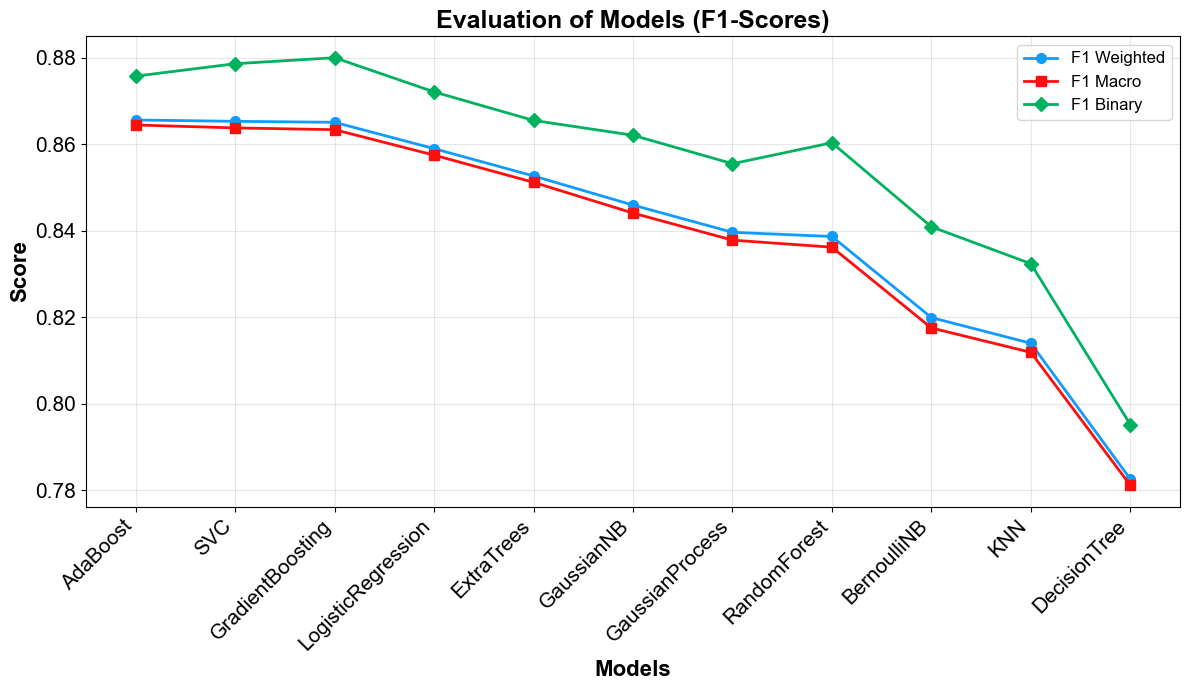

In [ ]:
metrics = ['F1 Weighted', 'F1 Macro', 'F1 Binary']
title = "Evaluation of Models (F1-Scores)"

plot_models_results(results_df, metrics, title, "models_eval_f1.png")

#### Verify the stability of the model ranking

In [13]:

outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

scoring = {"roc_auc": "roc_auc", "f1_w": "f1_weighted", "recall": "recall",
           "precision": "precision", "ap": "average_precision"}

rows, cv_default = [], {}

for name, model in models.items():

    pipe = Pipeline([("preproc", full_preprocessor), ("model", clone(model))])

    r = cross_validate(pipe, X_dev, y_dev, cv=outer_cv, scoring=scoring, n_jobs=-1)

    cv_default[name] = r
    
    rows.append({"Model": name, **{f"{k}_mean": r[f"test_{k}"].mean() for k in scoring},
                 "roc_auc_sd": r["test_roc_auc"].std()})

    
cv_default_df = pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False).round(4).reset_index(drop=True)
cv_default_df.to_csv(OUT_DIR / "cls_cv_default.csv", index=False)
cv_default_df

,Model,roc_auc_mean,f1_w_mean,recall_mean,precision_mean,ap_mean,roc_auc_sd
0,RandomForest,0.9245,0.8557,0.8856,0.8600,0.9189,0.0187
1,GradientBoosting,0.9217,0.8606,0.8848,0.8672,0.9229,0.0196
2,AdaBoost,0.9192,0.8515,0.8679,0.8646,0.9188,0.0182
3,ExtraTrees,0.9177,0.8515,0.8848,0.8532,0.9170,0.0199
4,SVC,0.9142,0.8538,0.8995,0.8472,0.9159,0.0213
5,LogisticRegression,0.9140,0.8475,0.8709,0.8565,0.9089,0.0251
6,GaussianNB,0.9007,0.8262,0.8446,0.8420,0.9075,0.0244
7,GaussianProcess,0.8991,0.8274,0.8647,0.8315,0.9009,0.0211
8,BernoulliNB,0.8870,0.8040,0.8183,0.8262,0.9011,0.0261
9,KNN,0.8844,0.8223,0.8585,0.8279,0.8670,0.0218


#### The results of models after CV visualized

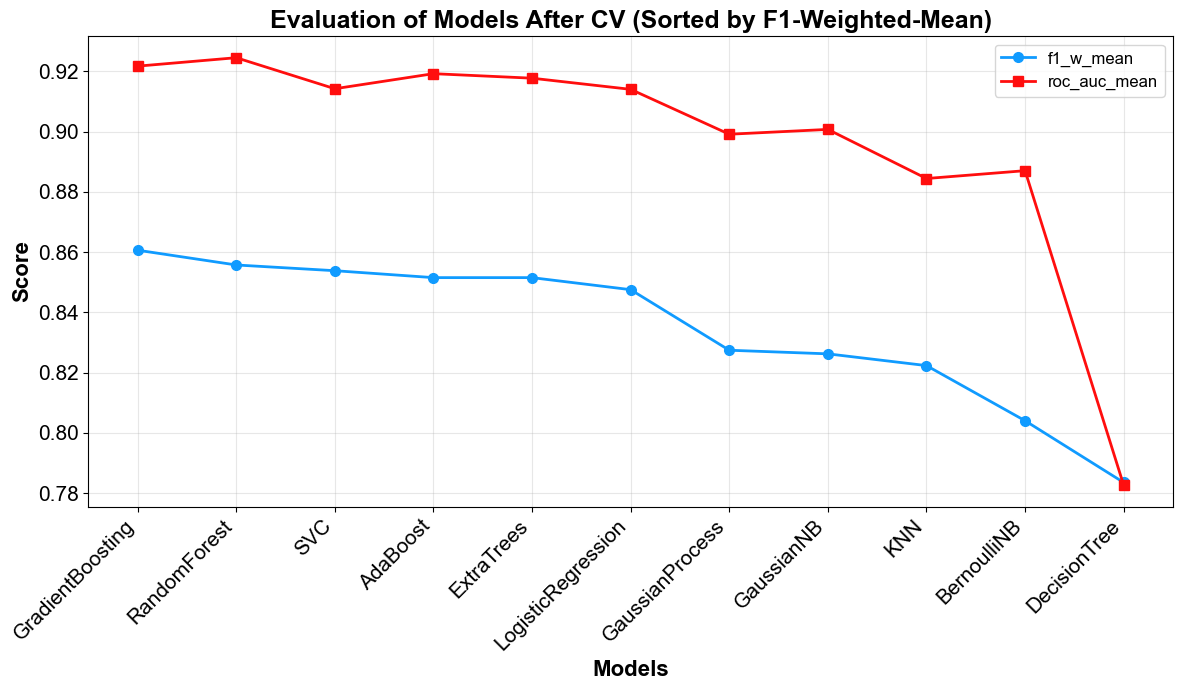

In [46]:
# Plot models performance after cv
metrics = ['f1_w_mean', "roc_auc_mean"]
title = "Evaluation of Models After CV (Sorted by F1-Weighted-Mean)"

plot_models_results(cv_default_df.sort_values("f1_w_mean", ascending=False).reset_index(drop=True),
                     metrics, title)


In [15]:
# Combine single-split and CV results for comparison
compare_df = results_df[['Model', 'F1 Weighted']].merge(
    cv_default_df, on='Model', how='inner'
)
compare_df = compare_df.rename(columns={'F1 Weighted': 'f1_single_split'})
compare_df

,Model,f1_single_split,roc_auc_mean,f1_w_mean,recall_mean,precision_mean,ap_mean,roc_auc_sd
0,AdaBoost,0.865602,0.9192,0.8515,0.8679,0.8646,0.9188,0.0182
1,SVC,0.865289,0.9142,0.8538,0.8995,0.8472,0.9159,0.0213
2,GradientBoosting,0.865065,0.9217,0.8606,0.8848,0.8672,0.9229,0.0196
3,LogisticRegression,0.858974,0.9140,0.8475,0.8709,0.8565,0.9089,0.0251
4,ExtraTrees,0.852656,0.9177,0.8515,0.8848,0.8532,0.9170,0.0199
5,GaussianNB,0.845923,0.9007,0.8262,0.8446,0.8420,0.9075,0.0244
6,GaussianProcess,0.839630,0.8991,0.8274,0.8647,0.8315,0.9009,0.0211
7,RandomForest,0.838660,0.9245,0.8557,0.8856,0.8600,0.9189,0.0187
8,BernoulliNB,0.819913,0.8870,0.8040,0.8183,0.8262,0.9011,0.0261
9,KNN,0.813971,0.8844,0.8223,0.8585,0.8279,0.8670,0.0218


#### Visualize results of both with and without cv for better comparison

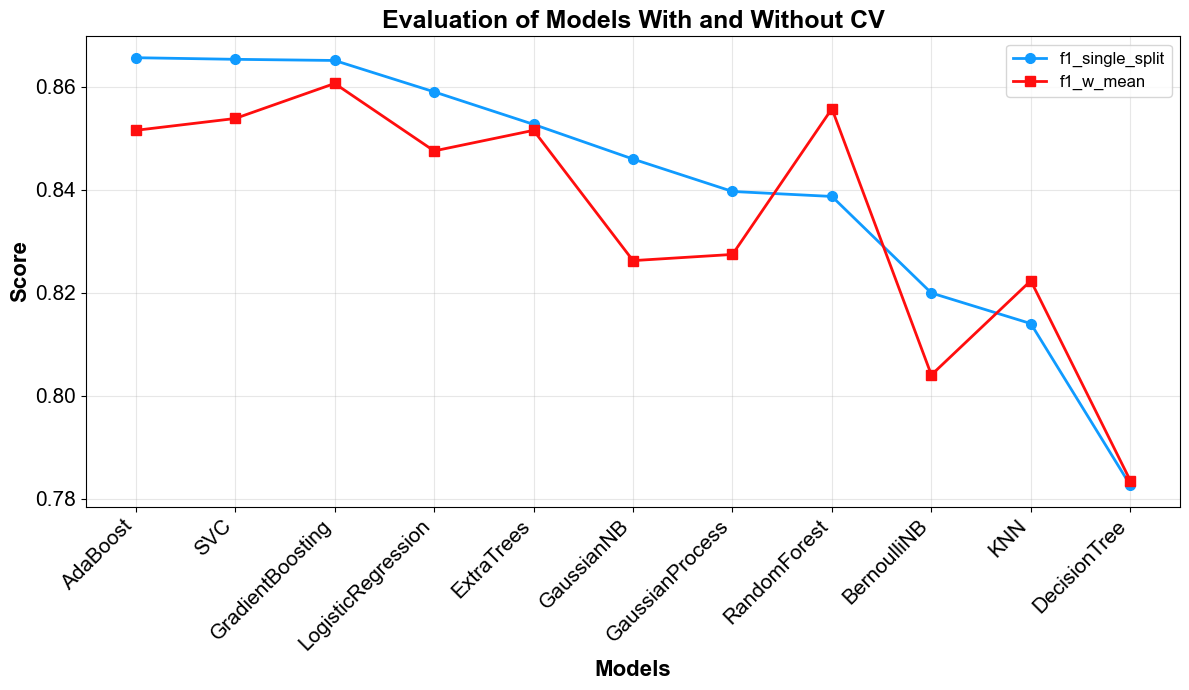

In [54]:
# Visualize single-split and CV results for comparison
metrics = ['f1_single_split', 'f1_w_mean']
title = "Evaluation of Models With and Without CV"

plot_models_results(compare_df, metrics, title, "models_eval_sing_mean.png")


### 11) Nested cross-validation with hyperparameter tuning


In [22]:

spaces = {
 "RandomForest": (RandomForestClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(100,500), "max_depth":[None,3,5,8], "min_samples_leaf": randint(1,10), "max_features":["sqrt",0.5]}),
 "ExtraTrees": (ExtraTreesClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(100,500), "max_depth":[None,3,5,8], "min_samples_leaf": randint(1,10), "max_features":["sqrt",0.5]}),
 "GradientBoosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(50,300), "learning_rate": loguniform(0.01,0.3), "max_depth": randint(1,5), "subsample":[0.6,0.8,1.0]}),
 "AdaBoost": (AdaBoostClassifier(random_state=RANDOM_STATE),
    {"n_estimators": randint(50,400), "learning_rate": loguniform(0.01,1.5)}),
 "SVC": (SVC(probability=True, random_state=RANDOM_STATE),
    {"C": loguniform(0.1,30), "gamma": loguniform(1e-3,1e-1), "kernel":["rbf","linear"]}),
 "LogisticRegression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    {"C": loguniform(1e-2,1e2)}),
 "KNN": (KNeighborsClassifier(), {"n_neighbors": randint(3,30), "weights":["uniform","distance"]}),
}



nested_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)  # outer
rows, nested_store = [], {}

for name, (est, dist) in spaces.items():
    pipe = Pipeline([("preproc", full_preprocessor), ("model", est)])
    dist = {f"model__{k}": v for k, v in dist.items()}
    inner = RandomizedSearchCV(pipe, dist, n_iter=20, scoring="roc_auc",
                cv=StratifiedKFold(3, shuffle=True, random_state=1), n_jobs=-1, random_state=RANDOM_STATE)
    r = cross_validate(inner, X_dev, y_dev, cv=nested_cv, scoring=scoring, n_jobs=1)
    nested_store[name] = r
    rows.append({"Model": name, **{f"{k}_mean": r[f"test_{k}"].mean() for k in scoring},
                 "roc_auc_sd": r["test_roc_auc"].std()})

    
nested_df = pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False).round(4).reset_index(drop=True)
nested_df.to_csv(OUT_DIR / "cls_nested_cv_tuned.csv", index=False)
nested_df


,Model,roc_auc_mean,f1_w_mean,recall_mean,precision_mean,ap_mean,roc_auc_sd
0,RandomForest,0.9274,0.8603,0.8921,0.8616,0.9263,0.0223
1,GradientBoosting,0.9274,0.8545,0.8840,0.8588,0.9285,0.0206
2,AdaBoost,0.9232,0.8618,0.8841,0.8691,0.9215,0.0198
3,ExtraTrees,0.9222,0.8478,0.8899,0.8453,0.9254,0.0202
4,LogisticRegression,0.9162,0.8515,0.8759,0.8592,0.9102,0.0283
5,SVC,0.9120,0.8568,0.9003,0.8510,0.9041,0.0307
6,KNN,0.9029,0.8290,0.8783,0.8255,0.9004,0.0244


In [23]:
joblib.dump(nested_store, OUT_DIR / "nested_store.joblib")

['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Outputs\\cls_ml\\nested_store.joblib']

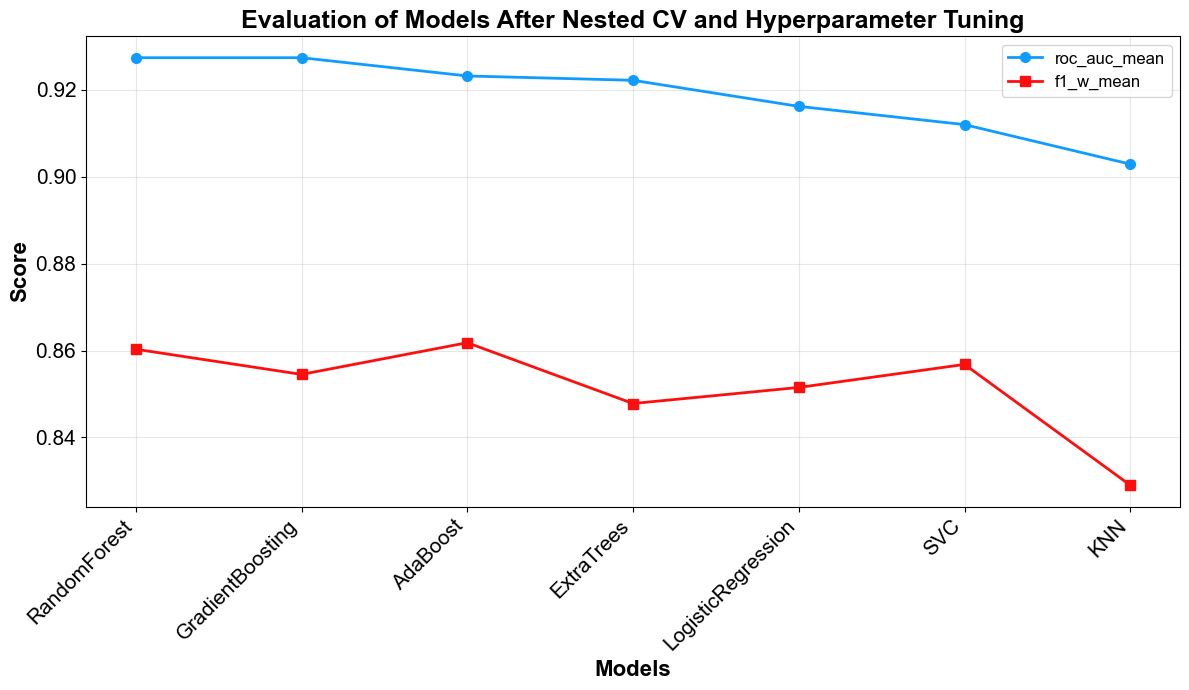

In [55]:
# Visualize nested CV + Hyperparameter tuning
metrics = ['roc_auc_mean', 'f1_w_mean']
title = "Evaluation of Models After Nested CV and Hyperparameter Tuning"

plot_models_results(nested_df, metrics, title, "models_eval_nested_Hyp.png")


#### Paired comparison of default vs. tuned models
For each model, the ROC-AUC of the tuned version was compared with the default version on the same 10 outer folds. Differences were tested with a paired t-test using the Nadeau-Bengio correction for overlapping training sets. Seven comparisons were made, so p < 0.007 (0.05/7) is the Bonferroni-corrected significance level.

In [25]:
def nb_paired(a, b):
    """Paired diff over k folds with the Nadeau-Bengio corrected t-test (80/20 splits => test/train = 0.25)."""
    d = np.asarray(b) - np.asarray(a); k = len(d)
    se = np.sqrt((1/k + 0.25) * d.var(ddof=1))
    t = d.mean() / se; p = 2 * stats.t.sf(abs(t), k - 1)
    return d.mean(), p
rows = []
for name in nested_store:
    a = cv_default[name]["test_roc_auc"][:10]; b = nested_store[name]["test_roc_auc"]
    diff, p = nb_paired(a, b); rows.append({"Model": name, "AUC diff (tuned-default)": round(diff, 4), "p (corrected)": round(p, 3)})
pd.DataFrame(rows)

,Model,AUC diff (tuned-default),p (corrected)
0,RandomForest,0.0024,0.574
1,ExtraTrees,0.0048,0.355
2,GradientBoosting,0.0046,0.514
3,AdaBoost,0.0038,0.179
4,SVC,-0.0023,0.744
5,LogisticRegression,0.0003,0.835
6,KNN,0.0189,0.024


### 12) Build the ensemble models

#### Cross-validated performance of the ensembles
Voting (AdaBoost + SVC + Gradient Boosting, soft voting) and Stacking (AdaBoost + SVC + Gradient Boosting + Extra Trees + Gaussian NB, logistic-regression meta-learner) were evaluated on the same outer folds as the single models. The printed lines are paired comparisons of ROC-AUC (difference, p-value): stacking vs voting, and stacking vs tuned Random Forest.

In [26]:
ada = lambda: AdaBoostClassifier(random_state=RANDOM_STATE)
svc = lambda: SVC(probability=True, random_state=RANDOM_STATE)
gb  = lambda: GradientBoostingClassifier(random_state=RANDOM_STATE)

ensembles = {
  "Voting":   VotingClassifier([("ADA", ada()), ("SVC", svc()), ("GB", gb())], voting="soft"),
  "Stacking": StackingClassifier([("ADA", ada()), ("SVC", svc()), ("GB", gb()),
              ("ET", ExtraTreesClassifier(random_state=RANDOM_STATE)), ("GNB", GaussianNB())],
              final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
}
ens_pipes = {n: Pipeline([("preproc", full_preprocessor), ("model", m)]) for n, m in ensembles.items()}

# Same outer CV as before
ens_rows, ens_cv = [], {}
for n, p in ens_pipes.items():
    r = cross_validate(p, X_dev, y_dev, cv=nested_cv, scoring=scoring, n_jobs=-1); ens_cv[n] = r
    ens_rows.append({"Model": n, **{f"{k}_mean": r[f"test_{k}"].mean().round(4) for k in scoring}, "roc_auc_sd": r["test_roc_auc"].std().round(4)})

ens_df = pd.DataFrame(ens_rows); ens_df.to_csv(OUT_DIR / "cls_ensembles_cv.csv", index=False)


In [27]:
ens_df

,Model,roc_auc_mean,f1_w_mean,recall_mean,precision_mean,ap_mean,roc_auc_sd
0,Voting,0.9251,0.8597,0.8863,0.8648,0.9269,0.0223
1,Stacking,0.9262,0.8565,0.8852,0.8610,0.9272,0.0213


In [28]:
print("Stacking vs Voting:", nb_paired(ens_cv["Voting"]["test_roc_auc"], ens_cv["Stacking"]["test_roc_auc"]))
print("Stacking vs tuned RF:", nb_paired(nested_store["RandomForest"]["test_roc_auc"], ens_cv["Stacking"]["test_roc_auc"]))

Stacking vs Voting: (np.float64(0.0010913978226833598), np.float64(0.5681245644055428))
Stacking vs tuned RF: (np.float64(-0.0011446353235341933), np.float64(0.7026523257811521))


In [93]:
joblib.dump(ens_cv, OUT_DIR / "ens_cv.joblib")

['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Outputs\\cls_ml\\ens_cv.joblib']

### 13) Threshold selection on out-of-fold predictions (training data only)

In [29]:
# Out-of-fold probabilities (3 x 5-fold, pooled), one set per ensemble
oof = {}
for n, p in ens_pipes.items():
    P = [cross_val_predict(p, X_dev, y_dev, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE+rep),
         method="predict_proba", n_jobs=-1)[:, 1] for rep in range(3)]
    oof[n] = (np.concatenate(P), np.concatenate([y_dev.values] * 3))


grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
def thr_table(p, y):
    return pd.DataFrame([{"thr": t, "recall": recall_score(y, (p >= t).astype(int)),
        "precision": precision_score(y, (p >= t).astype(int), zero_division=0),
        "F2": fbeta_score(y, (p >= t).astype(int), beta=2)} for t in grid])

thr_tables = {n: thr_table(*oof[n]) for n in oof}

def pick_rule_A(tbl, min_recall=0.90):
    return tbl[tbl.recall >= min_recall].thr.max()

LOCKED = {n: pick_rule_A(t) for n, t in thr_tables.items()}
print("Locked thresholds (Rule A, recall >= 0.90):", LOCKED)

sens = pd.DataFrame([{"Model": n, "min recall": mr, "threshold": pick_rule_A(t, mr),
        "precision": t.loc[t.thr == pick_rule_A(t, mr), "precision"].iloc[0].round(3)} for n, t in thr_tables.items() for mr in (0.85, 0.90, 0.95)])
sens.to_csv(OUT_DIR / "cls_threshold_sensitivity.csv", index=False); sens

Locked thresholds (Rule A, recall >= 0.90): {'Voting': np.float64(0.46), 'Stacking': np.float64(0.45)}


,Model,min recall,threshold,precision
0,Voting,0.85,0.57,0.882
1,Voting,0.90,0.46,0.853
2,Voting,0.95,0.32,0.799
3,Stacking,0.85,0.61,0.875
4,Stacking,0.90,0.45,0.852
5,Stacking,0.95,0.22,0.804


In [94]:
joblib.dump(oof, OUT_DIR / "oof.joblib")

['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Outputs\\cls_ml\\oof.joblib']

### 14) The Ensemble models evaluation
#### Discrimination (out-of-fold)

In [6]:
STYLE = {"Voting": ("#0022ff", "-", "o", "o"), "Stacking": ("#ff0000", "--", "s", "s")}   # color, line style, marker

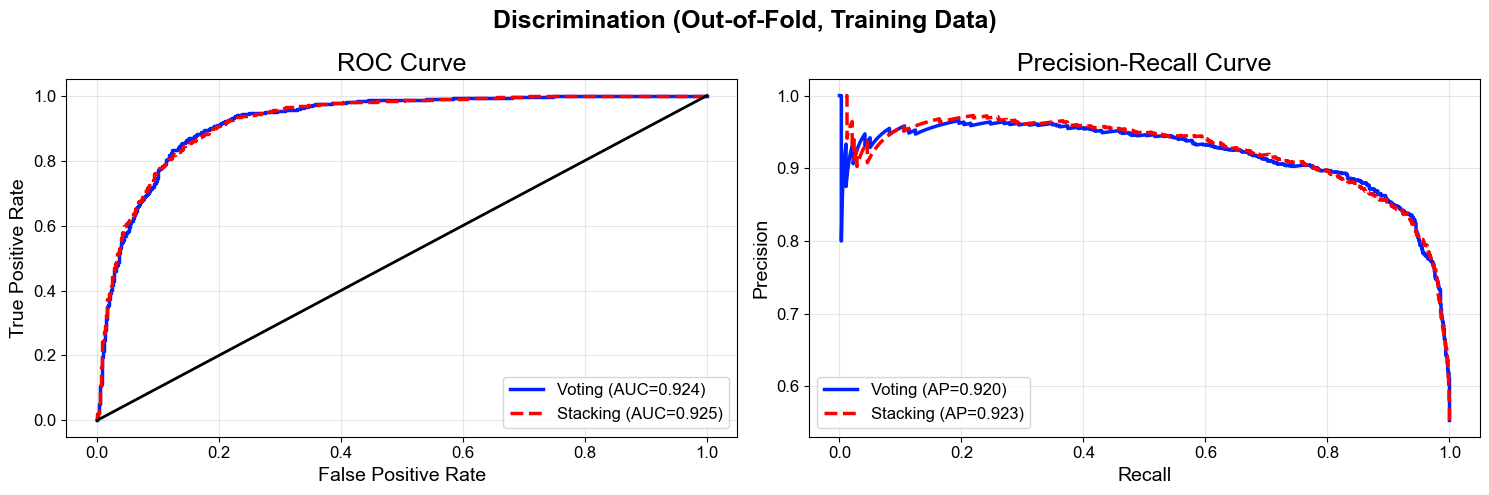

In [ ]:

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for n, (p, y) in oof.items():
    c, ls, _, _ = STYLE[n]
    fpr, tpr, _ = roc_curve(y, p)
    ax[0].plot(fpr, tpr, color=c, ls=ls, linewidth=2.5, label=f"{n} (AUC={roc_auc_score(y, p):.3f})")
    pr, rc, _ = precision_recall_curve(y, p)
    ax[1].plot(rc, pr, color=c, ls=ls, linewidth=2.5, label=f"{n} (AP={average_precision_score(y, p):.3f})")

ax[0].plot([0, 1], [0, 1], color="k", ls="-", linewidth=2)
ax[0].set_xlabel("False Positive Rate", fontsize=14); ax[0].set_ylabel("True Positive Rate", fontsize=14); ax[0].set_title("ROC Curve", fontsize=18)
ax[1].set_xlabel("Recall", fontsize=14); ax[1].set_ylabel("Precision", fontsize=14); ax[1].set_title("Precision-Recall Curve", fontsize=18)

for a in ax:
    a.tick_params(axis="both", labelsize=12); a.grid(alpha=0.3); a.legend(fontsize=12, loc="lower right" if a is ax[0] else "lower left")

plt.suptitle("Discrimination (Out-of-Fold, Training Data)", fontsize=18, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig_roc_pr_oof.png", dpi=300); plt.show()

#### Locked decision threshold

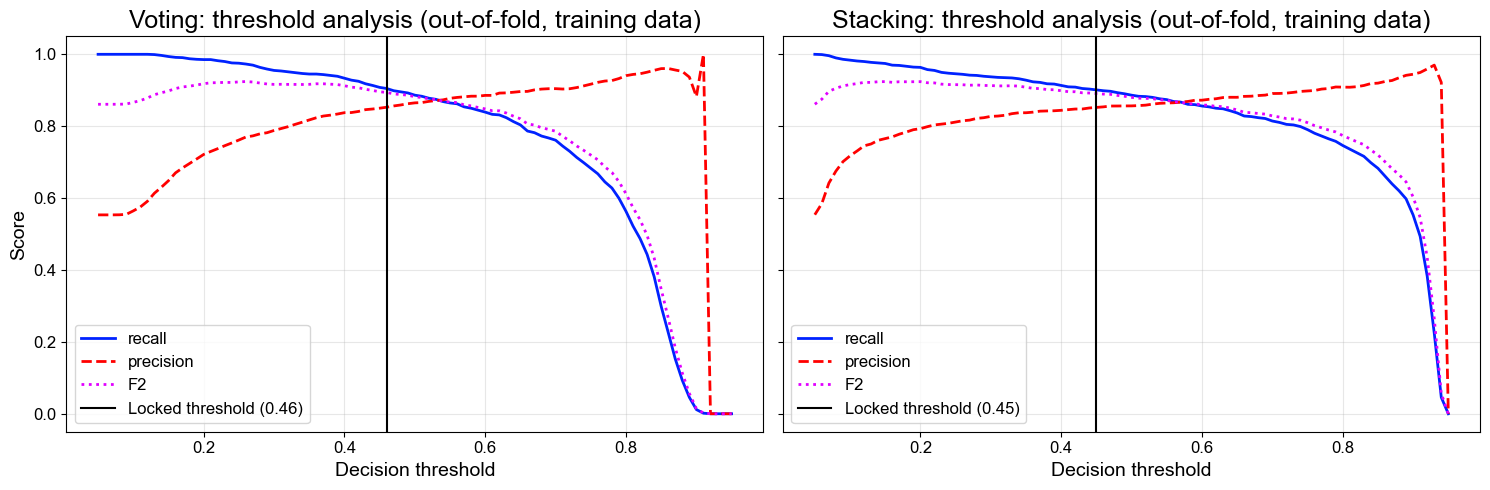

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for a, n in zip(ax, ["Voting", "Stacking"]):
    tbl = thr_tables[n]

    for c, s, color in [("recall", "-", "#0022ff"), ("precision", "--", "#ff0000"), ("F2", ":", "#e100ff")]: 
        a.plot(tbl.thr, tbl[c], s, color=color, label=c, linewidth=2)

    a.axvline(LOCKED[n], color="k", ls="-", label=f"Locked threshold ({LOCKED[n]:.2f})")
    a.set_title(f"{n}: threshold analysis (out-of-fold, training data)", fontsize=18)
    a.set_xlabel("Decision threshold", fontsize=14); a.grid(alpha=0.3); a.legend(fontsize=12)
    a.tick_params(axis="both", labelsize=12)

ax[0].set_ylabel("Score", fontsize=14); plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig_threshold_oof.png", dpi=300); plt.show()

- The decision threshold was chosen before any test-set evaluation, using out-of-fold predicted probabilities from the training data (three repeats of 5-fold CV). 
- The rule: the highest threshold at which recall is at least 0.90. 
- Locked thresholds: Voting 0.46, Stacking 0.45. 
- These values were not changed after the test set was evaluated.

### Clinical utility: decision curve and calibration (out-of-fold)
- **Net benefit** = (true positives per patient) − (false positives per patient) × t/(1−t)

In [2]:
oof = joblib.load(OUT_DIR / "oof.joblib")

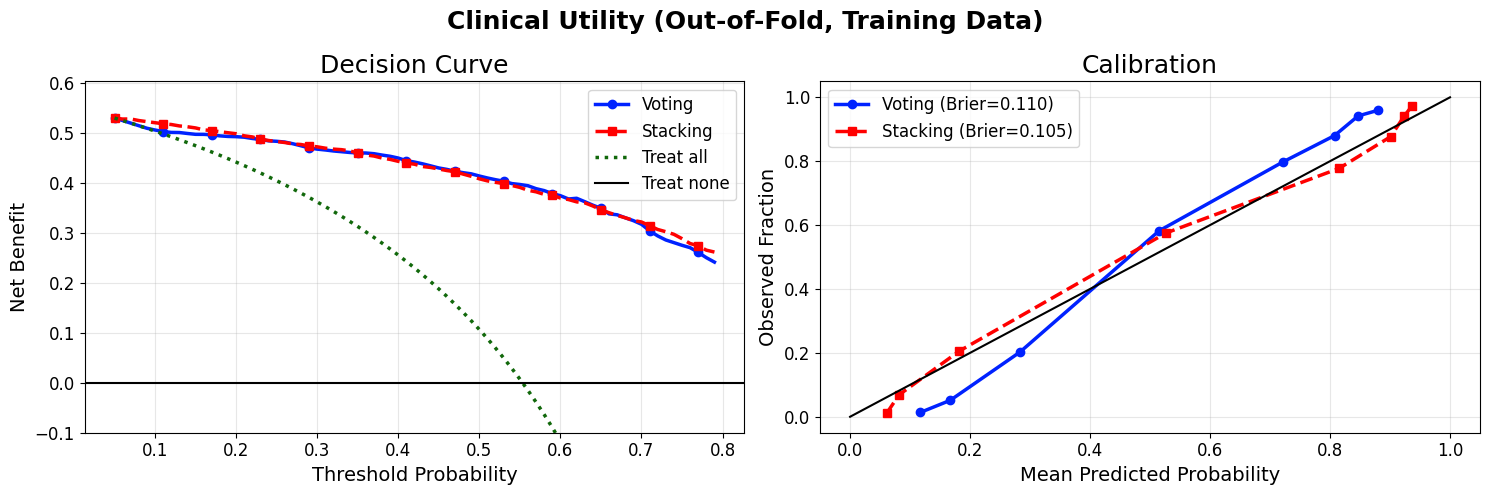

In [8]:
def net_benefit(y, p, t):
    pr = p >= t; n = len(y); tp = (pr & (y == 1)).sum(); fp = (pr & (y == 0)).sum()
    return tp / n - fp / n * t / (1 - t)

ts = np.arange(0.05, 0.80, 0.01)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

for n, (p, y) in oof.items():
    c, ls, m_dca, m_cal = STYLE[n]
    ax[0].plot(ts, [net_benefit(y, p, t) for t in ts], color=c, ls=ls, marker=m_dca, markevery=6, markersize=6, linewidth=2.5, label=n)
    
    fo, mp = calibration_curve(y, p, n_bins=8, strategy="quantile")
    ax[1].plot(mp, fo, color=c, ls=ls, marker=m_cal, markersize=6, linewidth=2.5, label=f"{n} (Brier={brier_score_loss(y, p):.3f})")

prev = y.mean()
ax[0].plot(ts, [prev - (1 - prev) * t / (1 - t) for t in ts], color="#11680b", ls=":", linewidth=2.5, label="Treat all")
ax[0].axhline(0, color="black", linewidth=1.5, label="Treat none")
ax[0].set_ylim(-0.1, prev + 0.05)
ax[0].set_xlabel("Threshold Probability", fontsize=14); ax[0].set_ylabel("Net Benefit", fontsize=14); ax[0].set_title("Decision Curve", fontsize=18)
ax[1].plot([0, 1], [0, 1], color="k", ls="-", linewidth=1.5)
ax[1].set_xlabel("Mean Predicted Probability", fontsize=14); ax[1].set_ylabel("Observed Fraction", fontsize=14); ax[1].set_title("Calibration", fontsize=18)
for a in ax:
    a.tick_params(axis="both", labelsize=12); a.grid(alpha=0.3); a.legend(fontsize=12)

plt.suptitle("Clinical Utility (Out-of-Fold, Training Data)", fontsize=18, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT_DIR_FIG / "fig_dca_calibration.png", dpi=300); plt.show()

### 15) The final retraining on full train set

In [37]:
# Final models: fit on ALL development data (the test set has not been touched)
final_models = {n: clone(p).fit(X_dev, y_dev) for n, p in ens_pipes.items()}
print("Locked thresholds:", LOCKED)

Locked thresholds: {'Voting': np.float64(0.46), 'Stacking': np.float64(0.45)}


### 16) The final evaluation on test set

In [ ]:

X_test = test.drop(columns=["HeartDisease"]); y_test = test["HeartDisease"]

X_test, y_test = drop_invalid_resting_bp(X_test, y_test); y_t = y_test.values

test_prob = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}

pd.DataFrame({"y_true": y_t, **{f"p_{n}": p for n, p in test_prob.items()}}).to_csv(OUT_DIR / "cls_test_predictions.csv", index=False)  # saved for later tests

def metrics_at(y, p, thr):
    pr = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pr), "Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
            "Precision": tp / (tp + fp) if tp + fp else np.nan, "F1": f1_score(y, pr), "F1-weighted": f1_score(y, pr, average="weighted"),
            "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Brier": brier_score_loss(y, p),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

# Bootstrap 95% CIs (2000 resamples of the test patients, seed fixed, CI = Confidence Interval)
rng = np.random.default_rng(RANDOM_STATE); B = 2000; n_test = len(y_t); idx = rng.integers(0, n_test, size=(B, n_test))

rows, boot_store = [], {}
for n in final_models:
    p = test_prob[n]; pt = metrics_at(y_t, p, LOCKED[n])
    bs = pd.DataFrame([metrics_at(y_t[i], p[i], LOCKED[n]) for i in idx if len(np.unique(y_t[i])) == 2])
    boot_store[n] = bs

    for k in ["Accuracy", "Sensitivity", "Specificity", "Precision", "F1", "F1-weighted", "ROC-AUC", "PR-AUC", "Brier"]:
        lo, hi = bs[k].quantile([0.025, 0.975])
        rows.append({"Model": n, "Threshold": LOCKED[n], "Metric": k, "Value": round(pt[k], 4), "CI low": round(lo, 4), "CI high": round(hi, 4)})

    rows.append({"Model": n, "Threshold": LOCKED[n], "Metric": "TN/FP/FN/TP", "Value": f"{pt['TN']}/{pt['FP']}/{pt['FN']}/{pt['TP']}", "CI low": "", "CI high": ""})
    
test_df = pd.DataFrame(rows); test_df.to_csv(OUT_DIR / "cls_test_results.csv", index=False); test_df

,Model,Threshold,Metric,Value,CI low,CI high
0,Voting,0.46,Accuracy,0.8768,0.8188,0.9275
1,Voting,0.46,Sensitivity,0.9079,0.8333,0.9639
2,Voting,0.46,Specificity,0.8387,0.7432,0.9216
3,Voting,0.46,Precision,0.8734,0.7957,0.9405
4,Voting,0.46,F1,0.8903,0.831,0.9367
5,Voting,0.46,F1-weighted,0.8765,0.8188,0.9275
6,Voting,0.46,ROC-AUC,0.9344,0.8864,0.9733
7,Voting,0.46,PR-AUC,0.9421,0.8896,0.9811
8,Voting,0.46,Brier,0.1025,0.0777,0.1302
9,Voting,0.46,TN/FP/FN/TP,52/10/7/69,,


#### McNemar test and the 0.5-threshold table

In [41]:
from scipy.stats import binomtest

pv = (test_prob["Voting"] >= LOCKED["Voting"]).astype(int)
ps = (test_prob["Stacking"] >= LOCKED["Stacking"]).astype(int)

b = int(((pv == y_t) & (ps != y_t)).sum()); c = int(((pv != y_t) & (ps == y_t)).sum())      # discordant pairs
print(f"McNemar exact (Voting right / Stacking wrong = {b}, Voting wrong / Stacking right = {c}): p = {binomtest(b, b + c, 0.5).pvalue:.3f}" if b + c else "No discordant pairs")

d_auc = boot_store["Stacking"]["ROC-AUC"].values - boot_store["Voting"]["ROC-AUC"].values
print("AUC difference (Stacking-Voting), 95% bootstrap CI:", np.round(np.percentile(d_auc, [2.5, 97.5]), 4))

# For transparency only: what the default 0.50 threshold would give
pd.DataFrame({n: {k: round(v, 4) for k, v in metrics_at(y_t, test_prob[n], 0.5).items()
                   if k in ("Sensitivity", "Specificity", "Precision", "F1")} for n in final_models})


McNemar exact (Voting right / Stacking wrong = 0, Voting wrong / Stacking right = 4): p = 0.125
AUC difference (Stacking-Voting), 95% bootstrap CI: [-0.0089  0.0154]


,Voting,Stacking
Sensitivity,0.8816,0.9211
Specificity,0.8548,0.8710
Precision,0.8816,0.8974
F1,0.8816,0.9091


### Visualize some of the important final results

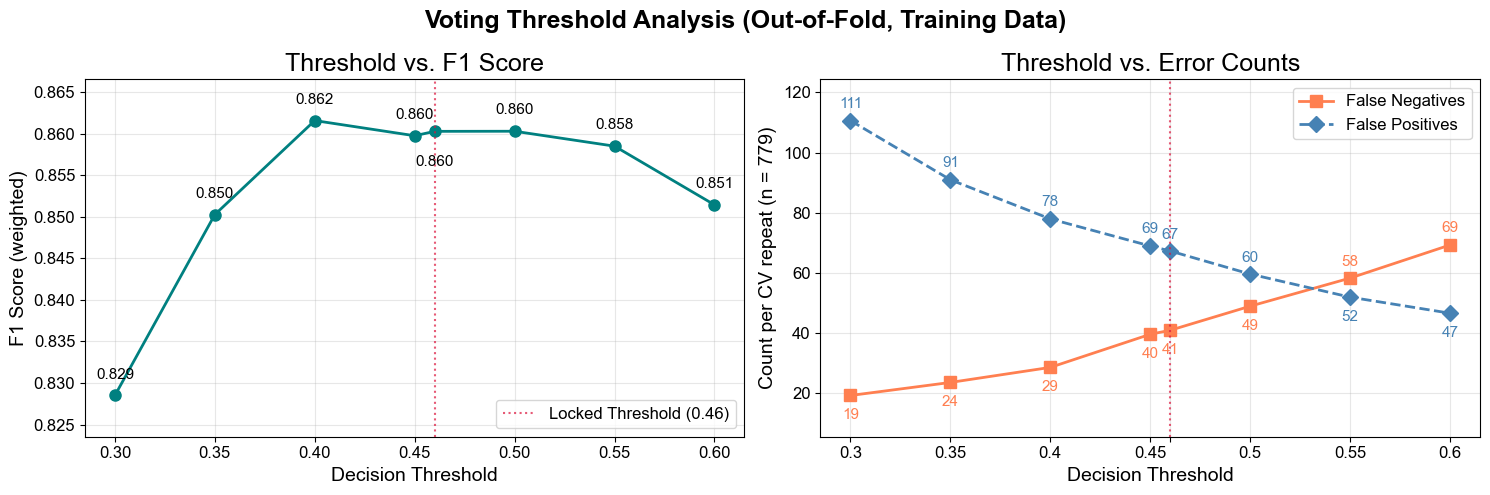

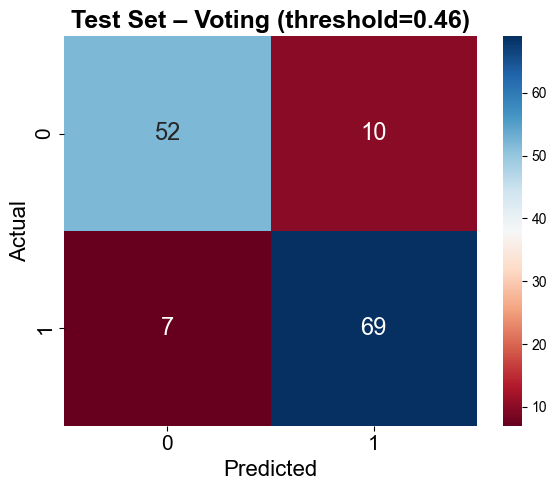

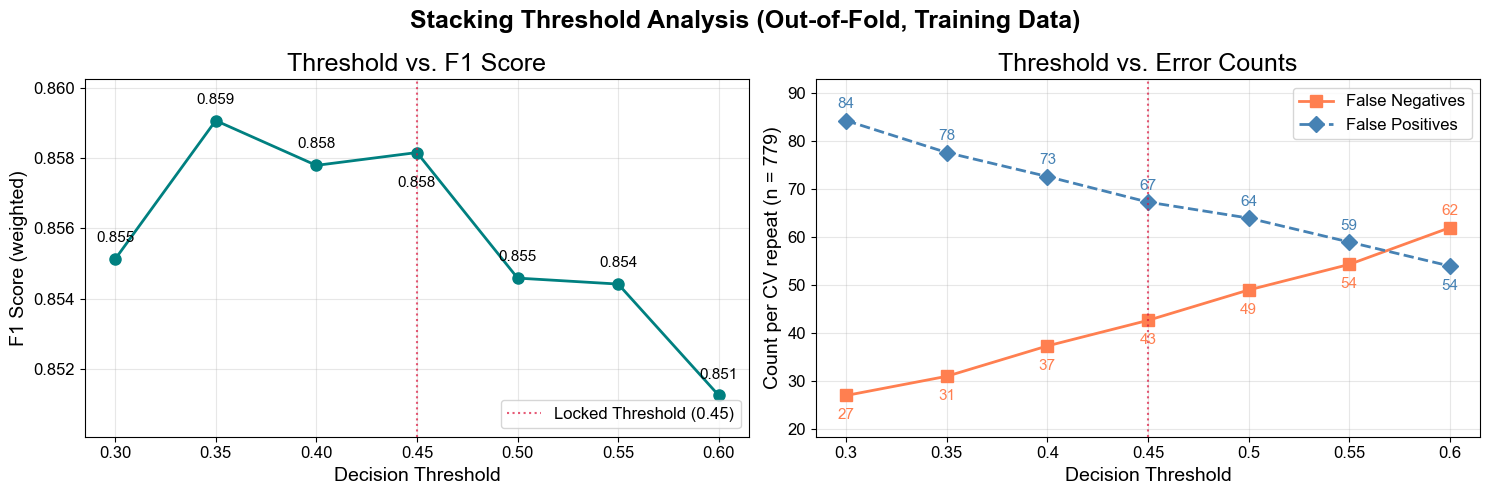

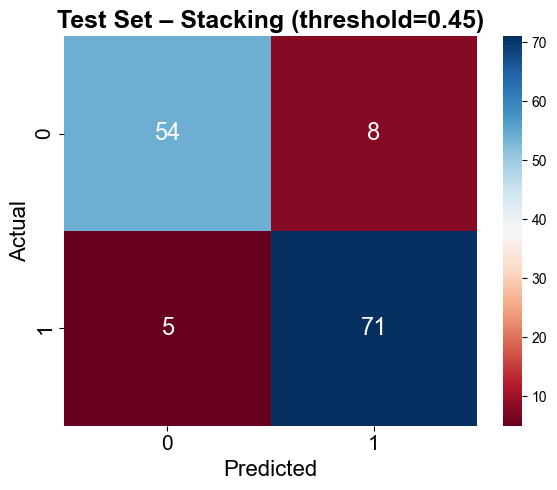

In [ ]:
# Figure: threshold analysis (out-of-fold, training data) + confusion matrix (test set, locked threshold)

for n in final_models:
    p_oof, y_oof = oof[n]
    n_rep = len(y_oof) // len(y_dev)                              # number of CV repeats pooled (3)
    thresholds = sorted(set([0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60] + [float(LOCKED[n])]))
    f1_scores, false_neg, false_pos = [], [], []
    for t in thresholds:
        pred = (p_oof >= t).astype(int)
        f1_scores.append(f1_score(y_oof, pred, average="weighted"))
        false_neg.append(((pred == 0) & (y_oof == 1)).sum() / n_rep)   # average count per CV repeat
        false_pos.append(((pred == 1) & (y_oof == 0)).sum() / n_rep)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # --- Left: Threshold vs F1 ---
    ax1.plot(thresholds, f1_scores, 'o-', color='teal', linewidth=2, markersize=8)
    ax1.set_xlabel('Decision Threshold', fontsize=14); ax1.set_ylabel('F1 Score (weighted)', fontsize=14)
    ax1.set_title('Threshold vs. F1 Score', fontsize=18)
    ax1.tick_params(axis='both', labelsize=12); ax1.grid(alpha=0.3)
    ax1.axvline(x=LOCKED[n], color='crimson', linestyle=':', linewidth=1.5, alpha=0.7, label=f'Locked Threshold ({LOCKED[n]:.2f})')
    ax1.legend(fontsize=12, loc='lower right')
    for x, y_ in zip(thresholds, f1_scores):
        below = np.isclose(x, LOCKED[n])                 # only 0.46 goes under
        ax1.annotate(
            f'{y_:.3f}', (x, y_),
            textcoords="offset points",
            xytext=(0, -17 if below else 10),
            va='top' if below else 'bottom',
            ha='center', fontsize=11
        )
    ax1.margins(y=0.15)

    # --- Right: Threshold vs FN and FP ---
    ax2.plot(thresholds, false_neg, 's-',  color='coral',     linewidth=2, markersize=8, label='False Negatives')
    ax2.plot(thresholds, false_pos, 'D--', color='steelblue', linewidth=2, markersize=8, label='False Positives')
    ax2.set_xlabel('Decision Threshold', fontsize=14); ax2.set_ylabel('Count per CV repeat (n = 779)', fontsize=14)
    ax2.set_title('Threshold vs. Error Counts', fontsize=18)
    ax2.set_xticks(thresholds); ax2.tick_params(axis='both', labelsize=12); ax2.set_xticklabels(i if i != 0.46 else "" for i in thresholds)
    ax2.grid(alpha=0.3)
    ax2.axvline(x=LOCKED[n], color='crimson', linestyle=':', linewidth=1.5, alpha=0.7)
    ax2.legend(fontsize=12); ax2.margins(y=0.15)
    for x, fn, fp in zip(thresholds, false_neg, false_pos):      # the higher line's label goes above, the lower line's below
        up, down = (9, -17)
        ax2.annotate(f'{fn:.0f}', (x, fn), textcoords="offset points", xytext=(0, up if fn >= fp else down), ha='center', color='coral',     fontsize=11)
        ax2.annotate(f'{fp:.0f}', (x, fp), textcoords="offset points", xytext=(0, up if fp > fn else down), ha='center', color='steelblue', fontsize=11)

    plt.suptitle(f'{n} Threshold Analysis (Out-of-Fold, Training Data)', fontsize=18, fontweight='bold')
    plt.tight_layout(); plt.savefig(OUT_DIR_FIG / f"fig4_{n.lower()}_threshold.png", dpi=300); plt.show()

    # --- Confusion matrix on the TEST set at the locked threshold (the single evaluation) ---
    cm_test = confusion_matrix(y_t, (test_prob[n] >= LOCKED[n]).astype(int), labels=[0, 1])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_test, annot=True, fmt="d", cmap="RdBu", annot_kws={"size": 17})
    plt.title(f"Test Set – {n} (threshold={LOCKED[n]:.2f})", fontsize=18, fontweight="bold")
    plt.xlabel("Predicted", fontsize=16); plt.ylabel("Actual", fontsize=16)
    plt.xticks(fontsize=15); plt.yticks(fontsize=15)
    plt.tight_layout(); plt.savefig(OUT_DIR_FIG / f"fig4_{n.lower()}_confusion.png", dpi=300); plt.show()

In [90]:
#--------------------------------------------
# Save the model & preprocessing pipeline
#--------------------------------------------

joblib.dump(final_models["Stacking"], PROJECT_ROOT / "Models/Classification/stacking_pipeline.joblib")
joblib.dump(final_models["Voting"], PROJECT_ROOT / "Models/Classification/voting_pipeline.joblib")
joblib.dump(LOCKED, PROJECT_ROOT / "Models/Classification/locked_thresholds.joblib")


['F:\\Desktop\\Projects\\AI-ML-DL\\Medical-Healthcare-Prediction-Framework\\Models\\Classification\\locked_thresholds.joblib']